# Machine Learning - Supervised
- Linear Regression

In [1]:
# import libs
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# load the dataset
hr = pd.read_csv('/Users/raghunandanms/Desktop/AICW_2.0/Spoke Engg/Unit 3-Understanding Machine Learning/Lab/Lab 21 House_Rent_Dataset.csv')
# show top 5 rows
hr.head()

,Posted On,BHK,Rent,Size,Floor,Area Type,Area Locality,City,Furnishing Status,Tenant Preferred,Bathroom,Point of Contact
0,2022-05-18,2,10000,1100,Ground out of 2,Super Area,Bandel,Kolkata,Unfurnished,Bachelors/Family,2,Contact Owner
1,2022-05-13,2,20000,800,1 out of 3,Super Area,"Phool Bagan, Kankurgachi",Kolkata,Semi-Furnished,Bachelors/Family,1,Contact Owner
2,2022-05-16,2,17000,1000,1 out of 3,Super Area,Salt Lake City Sector 2,Kolkata,Semi-Furnished,Bachelors/Family,1,Contact Owner
3,2022-07-04,2,10000,800,1 out of 2,Super Area,Dumdum Park,Kolkata,Unfurnished,Bachelors/Family,1,Contact Owner
4,2022-05-09,2,7500,850,1 out of 2,Carpet Area,South Dum Dum,Kolkata,Unfurnished,Bachelors,1,Contact Owner


In [3]:
# how many rows and cols
hr.shape

(4746, 12)

In [4]:
# information of the dataset
hr.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4746 entries, 0 to 4745
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype 
---  ------             --------------  ----- 
 0   Posted On          4746 non-null   object
 1   BHK                4746 non-null   int64 
 2   Rent               4746 non-null   int64 
 3   Size               4746 non-null   int64 
 4   Floor              4746 non-null   object
 5   Area Type          4746 non-null   object
 6   Area Locality      4746 non-null   object
 7   City               4746 non-null   object
 8   Furnishing Status  4746 non-null   object
 9   Tenant Preferred   4746 non-null   object
 10  Bathroom           4746 non-null   int64 
 11  Point of Contact   4746 non-null   object
dtypes: int64(4), object(8)
memory usage: 445.1+ KB


In [6]:
hr['Posted On'].dtype

dtype('O')

In [7]:
hr['Rent'].dtype

dtype('int64')

In [8]:
# stats of the dataset
hr.describe()

,BHK,Rent,Size,Bathroom
count,4746.000000,4.746000e+03,4746.000000,4746.000000
mean,2.083860,3.499345e+04,967.490729,1.965866
std,0.832256,7.810641e+04,634.202328,0.884532
min,1.000000,1.200000e+03,10.000000,1.000000
25%,2.000000,1.000000e+04,550.000000,1.000000
50%,2.000000,1.600000e+04,850.000000,2.000000
75%,3.000000,3.300000e+04,1200.000000,2.000000
max,6.000000,3.500000e+06,8000.000000,10.000000


In [9]:
# are there any missing values?
hr.isnull().sum()

Posted On            0
BHK                  0
Rent                 0
Size                 0
Floor                0
Area Type            0
Area Locality        0
City                 0
Furnishing Status    0
Tenant Preferred     0
Bathroom             0
Point of Contact     0
dtype: int64

In [11]:
# missing value treatment
# 1. dropna method - drop rows
# 2. fillna method - fill rows with mean, median or mode

In [12]:
# list of col names
hr.columns

Index(['Posted On', 'BHK', 'Rent', 'Size', 'Floor', 'Area Type',
       'Area Locality', 'City', 'Furnishing Status', 'Tenant Preferred',
       'Bathroom', 'Point of Contact'],
      dtype='object')

In [13]:
hr = hr.drop(['Posted On'], axis=1)
hr.columns

Index(['BHK', 'Rent', 'Size', 'Floor', 'Area Type', 'Area Locality', 'City',
       'Furnishing Status', 'Tenant Preferred', 'Bathroom',
       'Point of Contact'],
      dtype='object')

pip install xgboost category-encoder

In [14]:
# importing ml libs
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.svm import SVR
import sklearn.metrics as mt
import xgboost as xgb
import category_encoders as ce
from sklearn.preprocessing import MinMaxScaler

In [16]:
hr.columns

Index(['BHK', 'Rent', 'Size', 'Floor', 'Area Type', 'Area Locality', 'City',
       'Furnishing Status', 'Tenant Preferred', 'Bathroom',
       'Point of Contact'],
      dtype='object')

In [17]:
hr = hr.drop(['Floor', 'Area Locality'], axis=1)
hr.columns

Index(['BHK', 'Rent', 'Size', 'Area Type', 'City', 'Furnishing Status',
       'Tenant Preferred', 'Bathroom', 'Point of Contact'],
      dtype='object')

In [18]:
# data splitting - 100% - 80% training set and 20% testing set
X = hr.drop(columns='Rent')
y = hr['Rent']

In [19]:
X.head()

,BHK,Size,Area Type,City,Furnishing Status,Tenant Preferred,Bathroom,Point of Contact
0,2,1100,Super Area,Kolkata,Unfurnished,Bachelors/Family,2,Contact Owner
1,2,800,Super Area,Kolkata,Semi-Furnished,Bachelors/Family,1,Contact Owner
2,2,1000,Super Area,Kolkata,Semi-Furnished,Bachelors/Family,1,Contact Owner
3,2,800,Super Area,Kolkata,Unfurnished,Bachelors/Family,1,Contact Owner
4,2,850,Carpet Area,Kolkata,Unfurnished,Bachelors,1,Contact Owner


In [20]:
# Encoding - LOO encoder
encoder = ce.LeaveOneOutEncoder(return_df=True)

In [21]:
X = encoder.fit_transform(X, y)

In [22]:
X.head()

,BHK,Size,Area Type,City,Furnishing Status,Tenant Preferred,Bathroom,Point of Contact
0,2,1100,18676.943967,11648.319312,22468.505513,31216.953238,2,16706.291757
1,2,800,18672.853988,11629.198853,38727.130222,31214.048795,1,16703.181337
2,2,1000,18674.080982,11634.934990,38728.463556,31214.920128,1,16704.114463
3,2,800,18676.943967,11648.319312,22468.505513,31216.953238,1,16706.291757
4,2,850,52405.438398,11653.099426,22469.883682,42185.583836,1,16707.069362


In [23]:
# standardization - scaling
scaler = MinMaxScaler()
X = scaler.fit_transform(X)
# y = scaler.transform(y)

In [24]:
X

array([[0.2       , 0.13642053, 0.27316184, ..., 0.01795978, 0.11111111,
        0.00321938],
       [0.2       , 0.09887359, 0.27307371, ..., 0.01780886, 0.        ,
        0.00316481],
       [0.2       , 0.12390488, 0.27310014, ..., 0.01785413, 0.        ,
        0.00318118],
       ...,
       [0.4       , 0.21777222, 0.99968293, ..., 0.01758247, 0.22222222,
        0.99965557],
       [0.4       , 0.1864831 , 0.99958912, ..., 0.99558704, 0.11111111,
        0.99954076],
       [0.2       , 0.12390488, 0.99987054, ..., 0.58744851, 0.11111111,
        0.00319209]], shape=(4746, 8))

In [25]:
X_df = pd.DataFrame(X)
X_df.head()

,0,1,2,3,4,5,6,7
0,0.2,0.136421,0.273162,0.004388,0.009553,0.017960,0.111111,0.003219
1,0.2,0.098874,0.273074,0.004130,0.487075,0.017809,0.000000,0.003165
2,0.2,0.123905,0.273100,0.004207,0.487114,0.017854,0.000000,0.003181
3,0.2,0.098874,0.273162,0.004388,0.009553,0.017960,0.000000,0.003219
4,0.2,0.105131,0.999941,0.004452,0.009593,0.587919,0.000000,0.003233


In [26]:
# train test split func
X_train, X_test, y_train, y_test = train_test_split(X, y,
                                                   train_size=0.8,
                                                   random_state=42)

In [27]:
X_train.shape, X_test.shape

((3796, 8), (950, 8))

In [28]:
# train 
lr = LinearRegression()

In [29]:
model = lr.fit(X_train, y_train)

In [30]:
model

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [31]:
# pred
y_pred = model.predict(X_test)
y_pred

array([ 2.47948399e+04,  1.64745090e+04,  6.29900183e+04,  6.31263577e+04,
        1.00790970e+05,  3.97633715e+04,  7.49611434e+04,  1.33035079e+04,
        1.74718740e+05,  8.80125705e+03, -3.18756505e+02,  5.23636156e+03,
        3.55871285e+04,  1.14861384e+04,  2.54450768e+04,  4.33307342e+04,
        1.23354848e+05,  1.66611396e+03,  1.58450520e+04,  7.62441931e+04,
        5.11238384e+04, -1.15411571e+04,  6.03710075e+04,  2.78437744e+04,
        1.46424244e+05, -1.42828102e+04, -8.25251318e+03,  5.64952841e+04,
       -1.83937435e+04,  9.93623391e+02, -1.40260219e+04, -8.72491271e+03,
       -7.90951862e+02,  2.18447554e+04,  4.01832617e+04,  4.97706511e+04,
       -4.73821388e+03, -1.42168698e+04,  2.36595909e+04, -5.68739081e+03,
        2.08938140e+04,  1.88398235e+05,  1.81995094e+04, -1.05725484e+04,
        8.05411857e+04,  1.31091113e+04,  7.59802244e+04,  1.00508247e+05,
        1.98732581e+05,  3.30586758e+04,  1.43439235e+04,  6.27822290e+04,
        2.23404027e+04,  

In [32]:
# Evaluate the model
mse = mt.mean_squared_error(y_test, y_pred)
mae = mt.mean_absolute_error(y_test, y_pred)
r2 = mt.r2_score(y_test, y_pred)
print(f'The mean squared error is {mse}')
print(f'The mean absolute error is {mae}')
print(f'The R Squared Score is {r2}')

The mean squared error is 1931480573.993184
The mean absolute error is 22537.86430435476
The R Squared Score is 0.5153586519637792


In [33]:
# decision tree
dtr = DecisionTreeRegressor()
model_dtr = dtr.fit(X_train, y_train)
dtr_pred = model_dtr.predict(X_test)
dtr_pred

array([ 16000.,  12000.,  28000.,   8000.,  45000.,  17000.,  56000.,
         9500., 400000.,  15000.,  10000.,  12000.,  27000.,  16000.,
        15000.,   8000., 140000.,  12000.,   6000.,  60000.,  38000.,
         7500.,  23000.,  14000., 260000.,   5000.,   6000.,  16500.,
         6500.,  15000.,   5000.,  14000.,   5000.,  12000.,  25000.,
        25000.,   7500.,   6000.,  17000.,   7000.,  13000., 330000.,
        14000.,   6000.,  60000.,  14000.,  32000.,  65000., 350000.,
        15000.,  11000.,  35000.,  18000.,  12000.,  65000., 130000.,
        35000.,  40000.,   9000.,   9000.,  18000.,   5000., 130000.,
        12000.,  50000.,  20000.,  18000.,  15500.,  35000.,  30000.,
        13000.,  24000., 100000.,   7000.,  25000.,  35000.,  12000.,
        52000.,  35000.,  28000.,  14000.,  10000.,  33000.,  10000.,
        12000.,  45000.,  36000.,  18000.,  25000.,  27000., 250000.,
        35000.,  24000., 120000.,  13000.,  12000.,  11000.,   7000.,
        20000.,  240

In [34]:
mse_dtr = mt.mean_squared_error(y_test, dtr_pred)
mae_dtr = mt.mean_absolute_error(y_test, dtr_pred)
r2_dtr = mt.r2_score(y_test, dtr_pred)
print(f'The mean squared error is {mse_dtr}')
print(f'The mean absolute error is {mae_dtr}')
print(f'The r squared score is {r2_dtr}')

The mean squared error is 256216358.93894738
The mean absolute error is 1169.0947368421052
The r squared score is 0.9357109549756508


In [35]:
rfr = RandomForestRegressor(n_estimators=100)
model_rfr = rfr.fit(X_train, y_train)
rfr_pred = model_rfr.predict(X_test)

In [36]:
mse_rfr = mt.mean_squared_error(y_test, rfr_pred)
mae_rfr = mt.mean_absolute_error(y_test, rfr_pred)
r2_rfr = mt.r2_score(y_test, rfr_pred)
print(f'The mean squared error is {mse_rfr}')
print(f'The mean absolute error is {mae_rfr}')
print(f'The r squared score is {r2_rfr}')

The mean squared error is 255733310.3343128
The mean absolute error is 1405.1300631578947
The r squared score is 0.9358321600915962


## Machine Learning - Classification Algorithm 

In [37]:
# importing libs
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

In [38]:
# load the dataset
wdf = pd.read_csv('/Users/raghunandanms/Desktop/AICW_2.0/Spoke Engg/Unit 3-Understanding Machine Learning/Lab/Lab 22 winequality-red.csv')
wdf.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


In [39]:
wdf.columns

Index(['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar',
       'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density',
       'pH', 'sulphates', 'alcohol', 'quality'],
      dtype='object')

In [40]:
wdf.describe()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
count,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000
mean,8.319637,0.527821,0.270976,2.538806,0.087467,15.874922,46.467792,0.996747,3.311113,0.658149,10.422983,5.636023
std,1.741096,0.179060,0.194801,1.409928,0.047065,10.460157,32.895324,0.001887,0.154386,0.169507,1.065668,0.807569
min,4.600000,0.120000,0.000000,0.900000,0.012000,1.000000,6.000000,0.990070,2.740000,0.330000,8.400000,3.000000
25%,7.100000,0.390000,0.090000,1.900000,0.070000,7.000000,22.000000,0.995600,3.210000,0.550000,9.500000,5.000000
50%,7.900000,0.520000,0.260000,2.200000,0.079000,14.000000,38.000000,0.996750,3.310000,0.620000,10.200000,6.000000
75%,9.200000,0.640000,0.420000,2.600000,0.090000,21.000000,62.000000,0.997835,3.400000,0.730000,11.100000,6.000000
max,15.900000,1.580000,1.000000,15.500000,0.611000,72.000000,289.000000,1.003690,4.010000,2.000000,14.900000,8.000000


In [41]:
wdf.isnull().sum()

fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
quality                 0
dtype: int64

quality
5    681
6    638
7    199
4     53
8     18
3     10
Name: count, dtype: int64


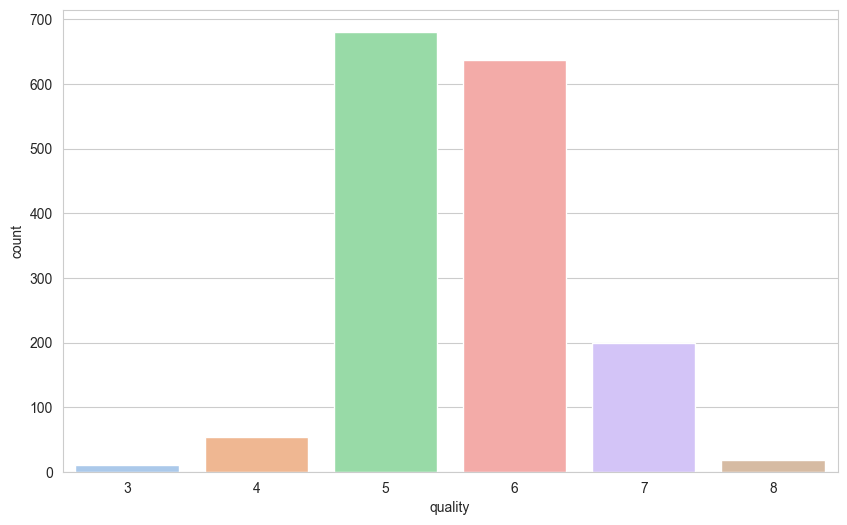

In [43]:
# visualization
sns.set_style(style='whitegrid')
print(wdf['quality'].value_counts())
fig = plt.figure(figsize=(10, 6))
sns.countplot(data=wdf, x='quality', palette='pastel')
plt.show()

In [45]:
num_cols = wdf.select_dtypes(include='number')
num_cols.corr()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
fixed acidity,1.000000,-0.256131,0.671703,0.114777,0.093705,-0.153794,-0.113181,0.668047,-0.682978,0.183006,-0.061668,0.124052
volatile acidity,-0.256131,1.000000,-0.552496,0.001918,0.061298,-0.010504,0.076470,0.022026,0.234937,-0.260987,-0.202288,-0.390558
citric acid,0.671703,-0.552496,1.000000,0.143577,0.203823,-0.060978,0.035533,0.364947,-0.541904,0.312770,0.109903,0.226373
residual sugar,0.114777,0.001918,0.143577,1.000000,0.055610,0.187049,0.203028,0.355283,-0.085652,0.005527,0.042075,0.013732
chlorides,0.093705,0.061298,0.203823,0.055610,1.000000,0.005562,0.047400,0.200632,-0.265026,0.371260,-0.221141,-0.128907
free sulfur dioxide,-0.153794,-0.010504,-0.060978,0.187049,0.005562,1.000000,0.667666,-0.021946,0.070377,0.051658,-0.069408,-0.050656
total sulfur dioxide,-0.113181,0.076470,0.035533,0.203028,0.047400,0.667666,1.000000,0.071269,-0.066495,0.042947,-0.205654,-0.185100
density,0.668047,0.022026,0.364947,0.355283,0.200632,-0.021946,0.071269,1.000000,-0.341699,0.148506,-0.496180,-0.174919
pH,-0.682978,0.234937,-0.541904,-0.085652,-0.265026,0.070377,-0.066495,-0.341699,1.000000,-0.196648,0.205633,-0.057731
sulphates,0.183006,-0.260987,0.312770,0.005527,0.371260,0.051658,0.042947,0.148506,-0.196648,1.000000,0.093595,0.251397


<Axes: >

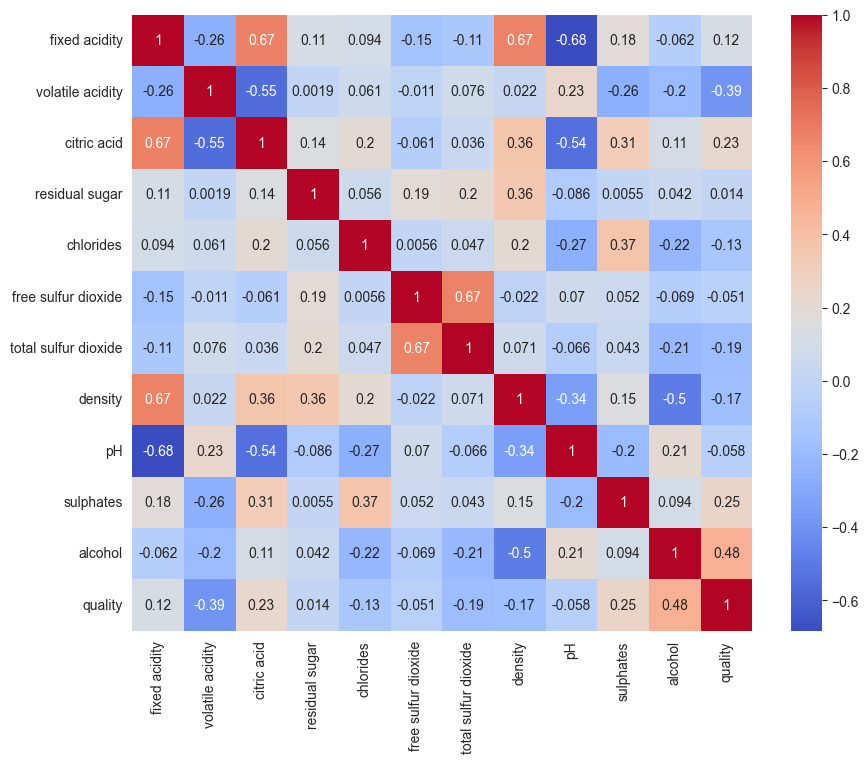

In [47]:
plt.figure(figsize=(10, 8))
sns.heatmap(num_cols.corr(), annot=True, cmap='coolwarm')

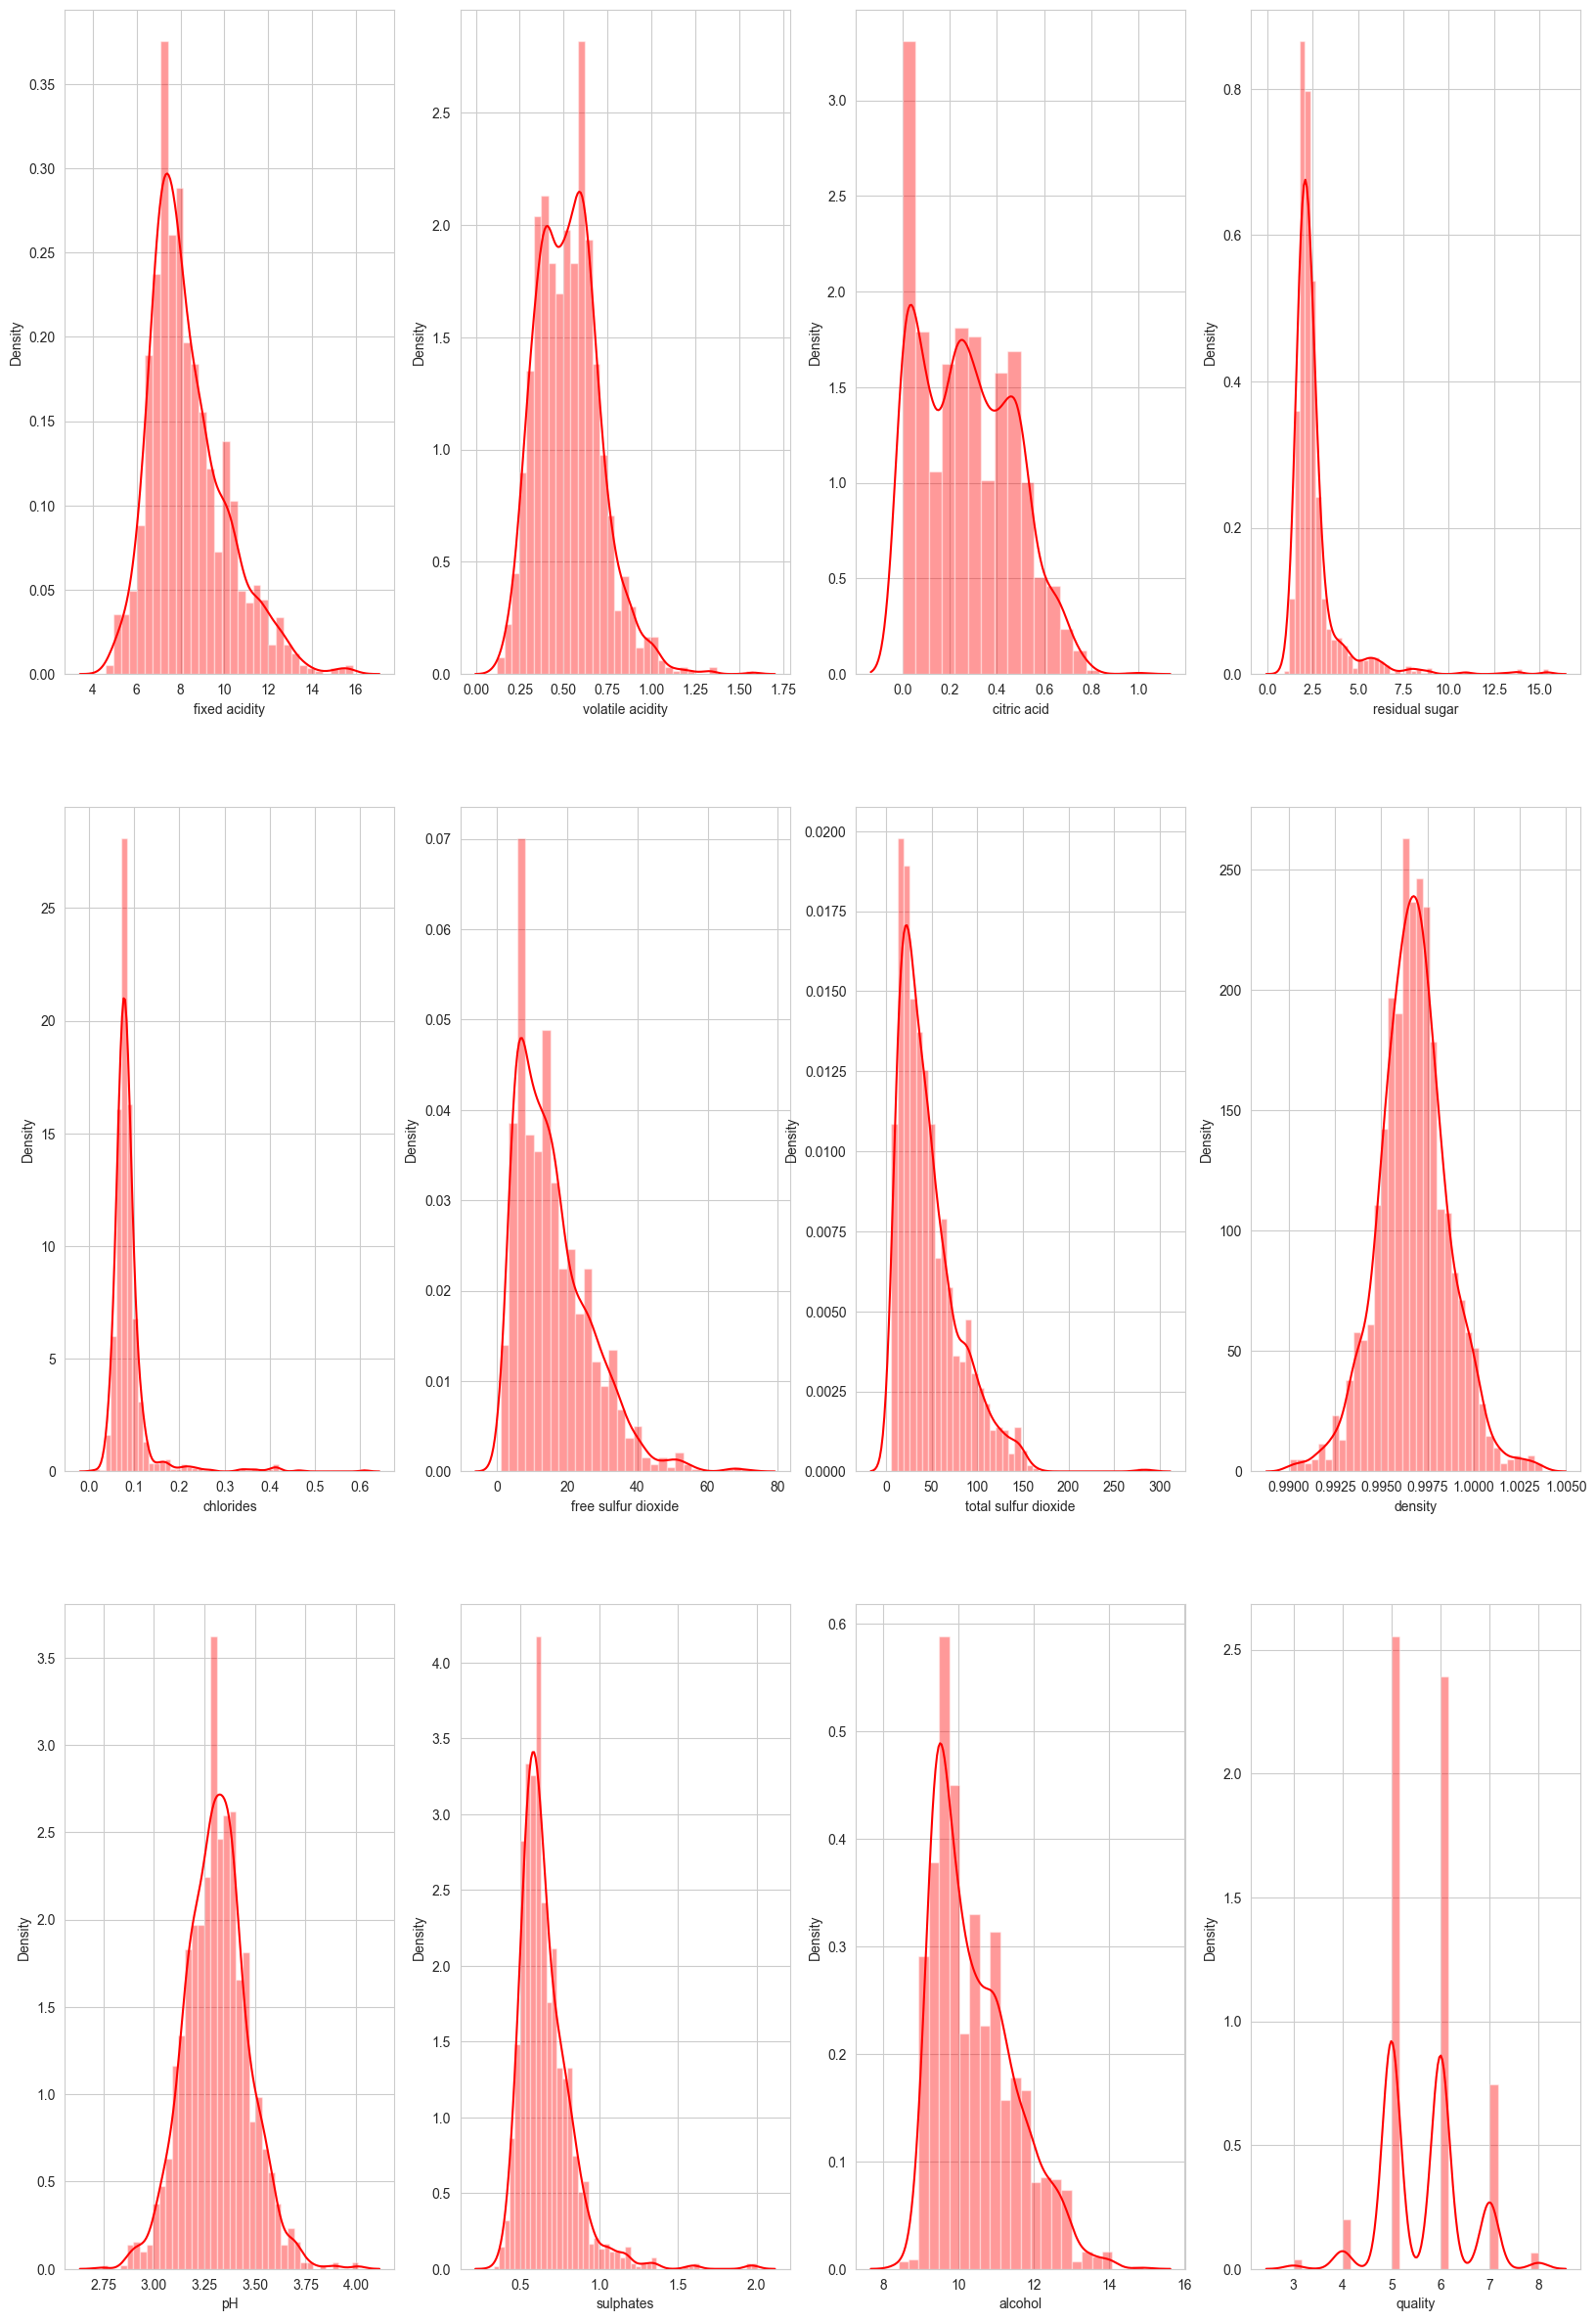

In [48]:
color = sns.color_palette('pastel')

fig, ax1 = plt.subplots(3, 4, figsize=(20, 30))
k = 0
columns = list(wdf.columns)
for i in range(3):
    for j in range(4):
        sns.distplot(wdf[columns[k]], ax = ax1[i][j], color='red')
        k = k + 1
plt.show()

In [49]:
# log transformation
def log_transformation(col):
    return np.log(col[0])

In [50]:
wdf['residual sugar'] = wdf[['residual sugar']].apply(log_transformation, axis=1)
wdf['chlorides'] = wdf[['chlorides']].apply(log_transformation, axis=1)
wdf['free sulfur dioxide'] = wdf[['free sulfur dioxide']].apply(log_transformation, axis=1)
wdf['total sulfur dioxide'] = wdf[['total sulfur dioxide']].apply(log_transformation, axis=1)
wdf['sulphates'] = wdf[['sulphates']].apply(log_transformation, axis=1)

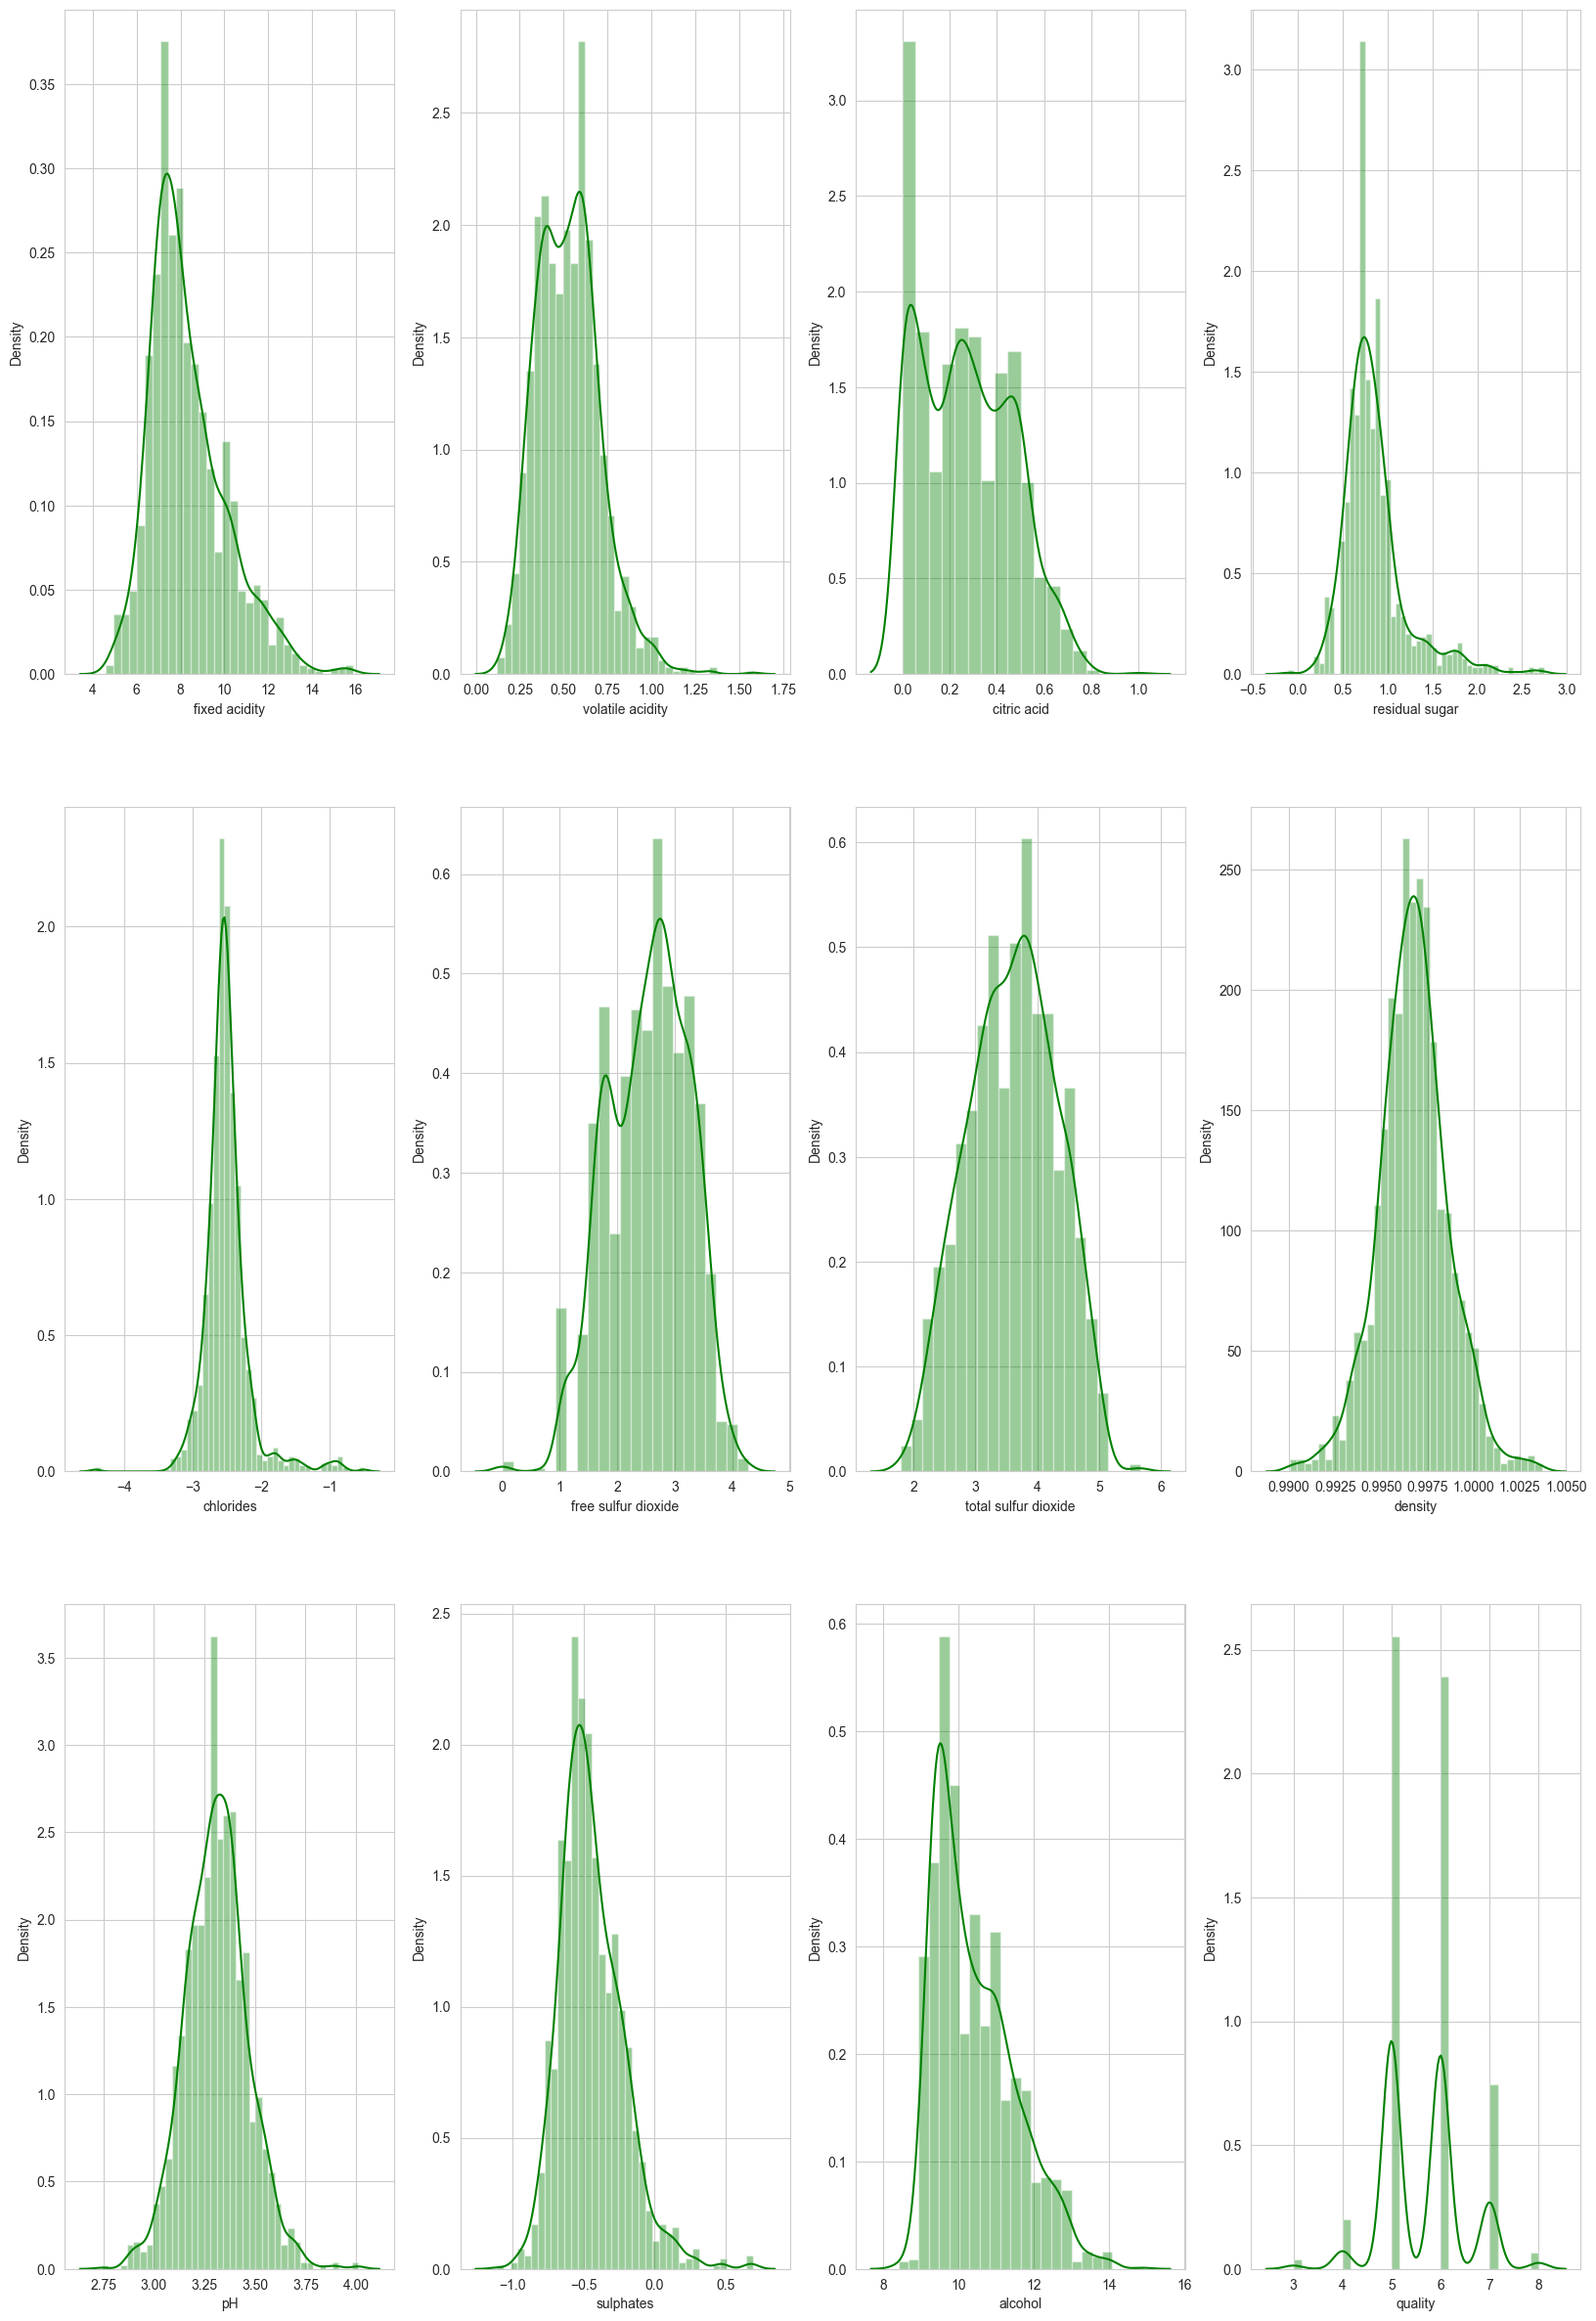

In [51]:
color = sns.color_palette('pastel')

fig, ax1 = plt.subplots(3, 4, figsize=(20, 30))
k = 0
columns = list(wdf.columns)
for i in range(3):
    for j in range(4):
        sns.distplot(wdf[columns[k]], ax = ax1[i][j], color='green')
        k = k + 1
plt.show()

In [52]:
wdf.corr()['quality'].sort_values(ascending=False)

quality                 1.000000
alcohol                 0.476166
sulphates               0.308642
citric acid             0.226373
fixed acidity           0.124052
residual sugar          0.023533
free sulfur dioxide    -0.050087
pH                     -0.057731
total sulfur dioxide   -0.170143
density                -0.174919
chlorides              -0.176140
volatile acidity       -0.390558
Name: quality, dtype: float64

In [53]:
# dataset split
x = wdf.drop(columns=['quality']) # x - independent variable
Y = wdf['quality'] # Y is dependent var

In [54]:
Y.value_counts()

quality
5    681
6    638
7    199
4     53
8     18
3     10
Name: count, dtype: int64

In [55]:
pip install imblearn


[notice] A new release of pip is available: 25.2 -> 26.2.1
[notice] To update, run: pip3.13 install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [57]:
from imblearn.over_sampling import SMOTE
oversample = SMOTE(k_neighbors=4)
x, Y = oversample.fit_resample(x.fillna(0), Y)

In [58]:
Y.value_counts()

quality
5    681
6    681
7    681
4    681
8    681
3    681
Name: count, dtype: int64

In [59]:
from sklearn.model_selection import train_test_split, cross_val_score

In [60]:
def classify(model, x, Y):
    x_train, x_test, Y_train, Y_test = train_test_split(x, Y, test_size=0.2,
                                                       random_state=9)
    model.fit(x_train, Y_train)
    return model.score(x_test, Y_test) * 100

In [61]:
# Apply logistic regression
from sklearn.linear_model import LogisticRegression
model = LogisticRegression()
LR_acc = classify(model, x, Y)
LR_acc

53.17848410757946

In [62]:
# apply RFC
from sklearn.ensemble import RandomForestClassifier
model_rf = RandomForestClassifier()
rf_acc = classify(model_rf, x, Y)
rf_acc

88.38630806845967